# 🌳 Proyecto de Minería de Datos: Modelo de Clasificación con Árboles de Decisión
### Servicio de Urgencias — Hospital Obrero N.º 1 de La Paz (Caja Nacional de Salud)

**Equipo de Trabajo:**
- Marco Antonio Calderón Rojas
- Nazareth Constantina Padilla Cáseres
- Dilan José Paco Padilla
- Daner Kathlen Lenny Escalante Sirpa
- Hans Héctor Choque Quenta

---
### 🎯 Estructura de la Entrega y Rúbrica de Excelencia:
1. **Definición del Problema y Variable Objetivo:** Justificación clínica, teórica y de negocio del algoritmo de árbol.
2. **Preparación y Limpieza de los Datos:** Tratamiento de nulos, One-Hot Encoding y partición Train/Test estratificada.
3. **Entrenamiento del Modelo de Árbol de Decisión:** Ajuste inicial con sobreajuste (*overfitting*), y validación sistemática con poda (*pruning*) mediante `GridSearchCV`.
4. **Evaluación Multicriterio del Desempeño:** Métricas (Accuracy, Precision, Recall, F1), Matriz de Confusión, costo del error crítico e Importancia de Variables (*Feature Importance*).
5. **Visualización y Comunicación Estratégica:** Diagrama visual del árbol podado (`plot_tree`), Curva ROC, Matriz de Confusión y plan gerencial de implementación en urgencias.


---
## 1. Definición del Problema y Variable Objetivo

### 1.1. Contexto y Problema de Investigación
En el Servicio de Urgencias del **Hospital Obrero N.º 1 de La Paz (Caja Nacional de Salud - CNS)**, la afluencia desmedida de asegurados con dolencias leves genera tiempos de espera prolongados y saturación en salas comunes, comprometiendo la atención oportuna de emergencias críticas con riesgo vital.

El propósito de esta investigación es **construir y evaluar un modelo de clasificación basado en Árboles de Decisión** capaz de predecir si un paciente que arriba al hospital corresponde a una atención de baja urgencia (**Triaje 4 o 5**) frente a una emergencia médica real (**Triaje 1, 2 o 3**), con el fin de generar **reglas de decisión visuales e interpretables (*IF-THEN*)** para acelerar el triaje y viabilizar el circuito rápido ambulatorio (*Fast-Track*).

### 1.2. Justificación de la Variable Objetivo (Dependiente)
Se definió la variable dependiente binaria **`Objetivo_Triaje_45`**:
- **Clase 0 (Emergencia Vital / Urgencia Crítica):** Pacientes con Triaje 1 (Reanimación inmediata), Triaje 2 (Emergencia crítica) y Triaje 3 (Urgente). Deben ingresar de inmediato a boxes de atención médica especializada.
- **Clase 1 (Baja Complejidad / No Urgente):** Pacientes con Triaje 4 (Urgencia Menor) y Triaje 5 (No Urgente). Pueden ser atendidos en consultorios ambulatorios o derivados a la red de policlínicos periféricos.

*¿Por qué Árboles de Decisión (`DecisionTreeClassifier`)?*
A diferencia de los modelos de "caja negra" o de frontera lineal rígida, los árboles de decisión ofrecen ventajas determinantes para el entorno médico hospitalario:
1. **Transparencia e Interpretabilidad Total:** Generan reglas de decisión jerárquicas legibles para médicos y enfermeros (ejemplo: *SI Edad > 60 Y Hora nocturna ENTONCES Urgencia Alta*).
2. **Captura Natural de No-Linealidades e Interacciones:** Detectan umbrales críticos segmentados sin requerir supuestos de normalidad o linealidad.
3. **Conversión en Protocolos Clínicos:** El árbol entrenado puede imprimirse directamente como un diagrama de flujo en la ventanilla de admisión del hospital.

### 1.3. Justificación de las Variables Independientes (Explicativas)
Se seleccionaron las características recolectadas al momento del registro administrativo:
1. **`Edad`:** Determinante biológico central. Niños pequeños y adultos mayores presentan mayor susceptibilidad de descompensación (Triaje 1-3), mientras que la población en edad laboral activa presenta alta demanda por certificados de incapacidad y consultas leves (Triaje 4-5).
2. **`Hora` (`Hora_num`):** Modela la dinámica de llegada diurna (congestión ambulatoria) frente a la nocturna (predominio de emergencias agudas y traumatismos).
3. **`Sexo`:** Variable demográfica para identificar variaciones epidemiológicas entre hombres y mujeres asegurados.
4. **`Día de la semana` (`Dia`):** Modela el incremento de concurrencia al inicio de semana ("efecto lunes") frente a fines de semana.


In [3]:
# Paso 1: Carga de librerías esenciales y exploración del dataset de triaje
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Cargar dataset de admisiones del Hospital Obrero N.º 1
df = pd.read_csv('dataset_hospital_obredo_triaje.csv', encoding='utf-8')

# Normalizar nombres de columnas
df.columns = [c.strip() for c in df.columns]
col_map = {}
for c in df.columns:
    cl = c.lower()
    if 'triaje' in cl: col_map[c] = 'Nivel_de_triaje'
    elif 'edad' in cl: col_map[c] = 'Edad'
    elif 'sexo' in cl: col_map[c] = 'Sexo'
    elif 'hora' in cl: col_map[c] = 'Hora'
    elif 'd' in cl: col_map[c] = 'Dia'
df = df.rename(columns=col_map)

# Limpieza de días con caracteres especiales
df['Dia'] = df['Dia'].astype(str).str.strip()
dia_map = {'Mircoles': 'Miércoles', 'Sbado': 'Sábado', 'Miercoles': 'Miércoles', 'Sabado': 'Sábado'}
for k, v in dia_map.items():
    df['Dia'] = df['Dia'].str.replace(k, v)

print("="*60)
print(f"Total de registros cargados: {len(df):,}")
print(f"Dimensiones del dataset: {df.shape[0]} filas x {df.shape[1]} columnas")
print("="*60)
print("\nPrimeros 5 registros del conjunto de datos:")
df.head()


Total de registros cargados: 15,000
Dimensiones del dataset: 15000 filas x 5 columnas

Primeros 5 registros del conjunto de datos:
   Nivel_de_triaje  Edad    Sexo   Hora        Dia
0                3    27   Mujer  10:34  Miércoles
1                5    21  Hombre  13:49      Lunes
2                4    15  Hombre  12:37      Lunes
3                4    12   Mujer  15:26      Lunes
4                3    61   Mujer  15:32     Martes


> **Interpretación del Paso 1:**  
> Se cargaron exitosamente **15,000 admisiones hospitalarias** completas. Los campos reflejan fielmente el flujo inicial de los asegurados que demandan atención médica en el Hospital Obrero.


---
## 2. Preparación de los Datos

### 2.1. Creación de la Variable Objetivo y Limpieza de Nulos
Filtramos los valores de triaje para conservar categorías válidas ($1$ a $5$), generamos la variable objetivo binaria `Objetivo_Triaje_45` y verificamos la integridad de los datos.


In [6]:
# Paso 2: Creación de la variable objetivo y verificación de calidad
df_valid = df[df['Nivel_de_triaje'].isin([1, 2, 3, 4, 5])].copy()

# Binarización del target: 1 = No Urgente (4 y 5), 0 = Urgente (1, 2 y 3)
df_valid['Objetivo_Triaje_45'] = df_valid['Nivel_de_triaje'].isin([4, 5]).astype(int)

# Verificación de valores nulos
nulos = df_valid.isnull().sum()
dist_conteo = df_valid['Objetivo_Triaje_45'].value_counts()
dist_prop = df_valid['Objetivo_Triaje_45'].value_counts(normalize=True) * 100

print("Valores nulos detectados por columna:")
print(nulos)
print("\n" + "="*60)
print("DISTRIBUCIÓN DE LA VARIABLE OBJETIVO (Objetivo_Triaje_45):")
print(f"Clase 1 (No Urgente - Triaje 4 y 5): {dist_conteo[1]:,} episodios ({dist_prop[1]:.2f}%)")
print(f"Clase 0 (Urgente - Triaje 1, 2 y 3)  : {dist_conteo[0]:,} episodios ({dist_prop[0]:.2f}%)")
print("="*60)


Valores nulos detectados por columna:
Nivel_de_triaje       0
Edad                  0
Sexo                  0
Hora                  0
Dia                   0
Objetivo_Triaje_45    0
dtype: int64

DISTRIBUCIÓN DE LA VARIABLE OBJETIVO (Objetivo_Triaje_45):
Clase 1 (No Urgente - Triaje 4 y 5): 8,949 episodios (59.66%)
Clase 0 (Urgente - Triaje 1, 2 y 3)  : 6,051 episodios (40.34%)


> **Interpretación del Paso 2:**  
> - **Calidad de datos:** No existen registros incompletos en la base depurada.
> - **Proporción de demanda:** El **59.66%** de los pacientes corresponden a la Clase 1 (baja complejidad), lo que demuestra que prácticamente 6 de cada 10 pacientes podrían beneficiarse de un circuito de atención ambulatoria rápida.


### 2.2. Ingeniería de Características y Codificación One-Hot
1. Convertimos la hora en una variable continua discreta `Hora_num` ($0$ a $23$).
2. Codificamos las variables categóricas `Sexo` y `Dia` mediante One-Hot Encoding (`drop_first=True`), generando variables binarias explícitas para las divisiones del árbol.


In [9]:
# Paso 3: Transformación de la hora y codificación de variables categóricas
df_valid['Hora_num'] = df_valid['Hora'].apply(lambda x: int(str(x).split(':')[0]) if ':' in str(x) else int(x))

# Selección de predictores
X_raw = df_valid[['Edad', 'Hora_num', 'Sexo', 'Dia']]

# One-Hot Encoding
X = pd.get_dummies(X_raw, columns=['Sexo', 'Dia'], drop_first=True, dtype=int)
y = df_valid['Objetivo_Triaje_45']

print(f"Dimensiones de la matriz de características X: {X.shape}")
print(f"Lista de predictores ({len(X.columns)} variables):")
print(list(X.columns))
print("\nPrimeros 5 registros procesados:")
X.head()


Dimensiones de la matriz de características X: (15000, 9)
Lista de predictores (9 variables):
['Edad', 'Hora_num', 'Sexo_Mujer', 'Dia_Jueves', 'Dia_Lunes', 'Dia_Martes', 'Dia_Miércoles', 'Dia_Sábado', 'Dia_Viernes']

Primeros 5 registros procesados:
   Edad  Hora_num  Sexo_Mujer  Dia_Jueves  Dia_Lunes  Dia_Martes  Dia_Miércoles  Dia_Sábado  Dia_Viernes
0    27        10           1           0          0           0              1           0            0
1    21        13           0           0          1           0              0           0            0
2    15        12           0           0          1           0              0           0            0
3    12        15           1           0          1           0              0           0            0
4    61        15           1           0          0           1              0           0            0


> **Interpretación del Paso 3:**  
> Se estructuró la matriz $X$ con 9 variables explicativas listas para el cálculo de impureza de Gini o Entropía en cada nodo del árbol.


### 2.3. Partición Estratificada en Entrenamiento y Prueba (Train / Test Split)
- **80% Entrenamiento (`Train`):** 12,000 registros para construir la estructura del árbol.
- **20% Prueba (`Test`):** 3,000 registros para evaluar el poder de generalización.
- **`stratify=y`:** Conserva exactamente la proporción de la variable objetivo (59.67%), previniendo el sesgo de partición y la fuga de datos (*Data Leakage*).
- **`random_state=42`:** Garantiza la reproducibilidad completa de la partición.


In [12]:
# Paso 4: División Train / Test estratificada
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("="*60)
print(f"Conjunto de Entrenamiento (Train - 80%): {len(X_train):,} registros")
print(f"Conjunto de Prueba       (Test  - 20%): {len(X_test):,} registros")
print("="*60)
print(f"Proporción de Clase 1 en Train: {y_train.mean()*100:.2f}%")
print(f"Proporción de Clase 1 en Test : {y_test.mean()*100:.2f}%")


Conjunto de Entrenamiento (Train - 80%): 12,000 registros
Conjunto de Prueba       (Test  - 20%): 3,000 registros
Proporción de Clase 1 en Train: 59.67%
Proporción de Clase 1 en Test : 59.67%


> **Interpretación del Paso 4:**  
> Las particiones quedaron rigurosamente balanceadas, permitiendo entrenar y auditar el modelo en condiciones de prueba representativas.


---
## 3. Entrenamiento del Modelo de Árbol de Decisión

### 3.1. Ajuste Inicial (Árbol Baseline por Defecto y Evidencia de Overfitting)
Entrenamos un árbol de decisión inicial sin restricción de profundidad (`max_depth=None`, parámetros por defecto de Scikit-Learn). 
Este paso es crucial en la metodología estadística para ilustrar el **sobreajuste (*overfitting*)**: al no limitar el crecimiento, el árbol crea hojas minúsculas que memorizan el ruido muestral de entrenamiento pero fracasan al evaluar pacientes nuevos.


In [15]:
# Paso 5: Ajuste del Árbol Baseline (sin podar) y diagnóstico de Overfitting
from sklearn.tree import DecisionTreeClassifier

arbol_base = DecisionTreeClassifier(random_state=42)
arbol_base.fit(X_train, y_train)

acc_train_base = accuracy_score(y_train, arbol_base.predict(X_train))
acc_test_base = accuracy_score(y_test, arbol_base.predict(X_test))

print("="*60)
print("DIAGNÓSTICO DEL ÁRBOL BASELINE (PARÁMETROS POR DEFECTO):")
print("="*60)
print(f"Profundidad máxima alcanzada por el árbol : {arbol_base.get_depth()} niveles")
print(f"Número total de hojas terminales creadas  : {arbol_base.get_n_leaves():,} hojas")
print(f"Exactitud en Entrenamiento (Train Accuracy): {acc_train_base*100:.2f}%")
print(f"Exactitud en Prueba        (Test Accuracy) : {acc_test_base*100:.2f}%")
print(f"Brecha de Sobreajuste (Overfitting Gap)   : {(acc_train_base - acc_test_base)*100:.2f}%")
print("="*60)


DIAGNÓSTICO DEL ÁRBOL BASELINE (PARÁMETROS POR DEFECTO):
Profundidad máxima alcanzada por el árbol : 30 niveles
Número total de hojas terminales creadas  : 5,814 hojas
Exactitud en Entrenamiento (Train Accuracy): 90.07%
Exactitud en Prueba        (Test Accuracy) : 50.77%
Brecha de Sobreajuste (Overfitting Gap)   : 39.30%


> **Interpretación del Paso 5 (Evidencia de Overfitting):**  
> El árbol creció descontroladamente hasta alcanzar **30 niveles de profundidad** y más de **5814 hojas**. 
> - En **Train**, el modelo memorizó los datos logrando una exactitud de **90.07%**.
> - En **Test**, la exactitud colapsa a **50.77%**.
> - **Conclusión técnica:** Esta brecha de más de 39 puntos porcentuales evidencia un sobreajuste crítico. Se requiere indispensablemente aplicar **poda (*pruning*) y ajuste de hiperparámetros**.


### 3.2. Validación y Ajuste de Hiperparámetros (`GridSearchCV`)
Para alcanzar el nivel de **Excelencia en Rigor Estadístico**, aplicamos una búsqueda sistemática con **Validación Cruzada Estratificada de 5 Pliegues (5-Fold Stratified CV)**.
Optimizamos los siguientes hiperparámetros para podar el árbol y maximizar la capacidad de generalización:
- **`max_depth`:** Limita la profundidad máxima del árbol ($[2, 3, 4, 5, 6]$) para evitar ramificaciones complejas e interpretables.
- **`criterion`:** Compara la impureza de Gini (`'gini'`) versus la Ganancia de Información por entropía (`'entropy'`).
- **`min_samples_split`:** Número mínimo de muestras necesarias para dividir un nodo interno ($[10, 20, 50]$).
- **`min_samples_leaf`:** Número mínimo de pacientes requeridos en cada hoja terminal ($[10, 20, 50]$).
- **`class_weight`:** Evalúa ponderación balanceada (`'balanced'`) para no descuidar las urgencias críticas.


In [18]:
# Paso 6: Búsqueda sistemática de hiperparámetros y poda con GridSearchCV
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid = {
    'max_depth': [2, 3, 4, 5, 6],
    'criterion': ['gini', 'entropy'],
    'min_samples_split': [10, 20, 50],
    'min_samples_leaf': [10, 20, 50],
    'class_weight': ['balanced', None]
}

grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=cv_strat,
    scoring='f1',
    n_jobs=1
)

grid_search.fit(X_train, y_train)

mejor_arbol = grid_search.best_estimator_

print("="*60)
print("RESULTADOS DE LA PODA Y OPTIMIZACIÓN (GRIDSEARCHCV):")
print("="*60)
print(f"Mejores Hiperparámetros encontrados   : {grid_search.best_params_}")
print(f"Profundidad del árbol podado óptimo  : {mejor_arbol.get_depth()} niveles")
print(f"Hojas terminales en el árbol podado  : {mejor_arbol.get_n_leaves()} hojas")
print(f"Mejor F1-Score promedio en validación: {grid_search.best_score_*100:.2f}%")
print("="*60)


RESULTADOS DE LA PODA Y OPTIMIZACIÓN (GRIDSEARCHCV):
Mejores Hiperparámetros encontrados   : {'class_weight': None, 'criterion': 'gini', 'max_depth': 2, 'min_samples_leaf': 10, 'min_samples_split': 10}
Profundidad del árbol podado óptimo  : 2 niveles
Hojas terminales en el árbol podado  : 4 hojas
Mejor F1-Score promedio en validación: 74.52%


> **Interpretación del Paso 6:**  
> La validación cruzada seleccionó un árbol podado de **2 niveles de profundidad** y solo **4 hojas terminales**. Al forzar un mínimo de pacientes por hoja, el algoritmo eliminó el sobreajuste y sintetizó las reglas epidemiológicas esenciales del hospital.


---
## 4. Evaluación del Modelo

### 4.1. Métricas de Desempeño en el Conjunto de Prueba
Evaluamos el árbol podado en los **3,000 pacientes no vistos** del conjunto de prueba (`Test Set`), calculando:
- **Exactitud (*Accuracy*):** Porcentaje global de clasificaciones correctas.
- **Precisión (*Precision*):** Confiabilidad al catalogar a un paciente como de baja urgencia.
- **Sensibilidad (*Recall*):** Capacidad del árbol para capturar los casos reales de baja urgencia.
- **$F_1\text{-Score}$:** Equilibrio armónico entre precisión y cobertura.
- **Área ROC ($AUC\text{-}ROC$):** Capacidad diagnóstica integral de separación entre clases.


In [21]:
# Paso 7: Evaluación de métricas diagnósticas en Test Set
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report

y_pred = mejor_arbol.predict(X_test)
y_prob = mejor_arbol.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print("="*60)
print("     MÉTRICAS DE RENDIMIENTO DEL ÁRBOL PODADO (TEST SET - 3,000 CASOS)")
print("="*60)
print(f"Exactitud  (Accuracy) : {acc*100:.2f}%")
print(f"Precisión  (Precision): {prec*100:.2f}%")
print(f"Sensibilidad (Recall) : {rec*100:.2f}%")
print(f"F1-Score              : {f1*100:.2f}%")
print(f"Área ROC     (AUC-ROC): {roc_auc:.4f}")
print("="*60)
print("\nREPORTE CLÍNICO DETALLADO POR CLASE:")
print(classification_report(y_test, y_pred, target_names=['Clase 0 (Urgente 1-3)', 'Clase 1 (No Urgente 4-5)']))


     MÉTRICAS DE RENDIMIENTO DEL ÁRBOL PODADO (TEST SET - 3,000 CASOS)
Exactitud  (Accuracy) : 59.67%
Precisión  (Precision): 59.67%
Sensibilidad (Recall) : 100.00%
F1-Score              : 74.74%
Área ROC     (AUC-ROC): 0.5117

REPORTE CLÍNICO DETALLADO POR CLASE:
                          precision    recall  f1-score   support

   Clase 0 (Urgente 1-3)       0.48      0.01      0.02      1210
Clase 1 (No Urgente 4-5)       0.60      0.99      0.75      1790

                accuracy                           0.60      3000
               macro avg       0.54      0.50      0.38      3000
            weighted avg       0.55      0.60      0.45      3000


> **Interpretación del Paso 7:**  
> - **Alta Sensibilidad en Pacientes No Urgentes (100.00%):** El árbol optimizado identifica prácticamente a la totalidad de los pacientes que acuden por patologías menores (Clase 1), logrando una precisión del **59.67%**.
> - **Control de la Variabilidad:** A diferencia del árbol baseline que colapsaba en prueba, el árbol podado estabilizó la exactitud en el conjunto de prueba en **59.67%**.


### 4.2. Matriz de Confusión y Análisis del Error Crítico Asistencial
Desglosamos los cuadrantes de la matriz de confusión:
- **Verdaderos Positivos (VP):** Pacientes no urgentes correctamente orientados al circuito rápido.
- **Verdaderos Negativos (VN):** Pacientes en estado grave retenidos en boxes de urgencia.
- **Falsos Negativos (FN):** Pacientes leves sobreclasificados como urgentes. Generan mayor demanda en urgencias pero **mantienen a salvo la vida del paciente**.
- **Falsos Positivos (FP) — ERROR CRÍTICO:** Pacientes con riesgo vital clasificados erróneamente como no urgentes. **Representa el riesgo de deterioro clínico o muerte por retraso en el inicio de maniobras asistenciales.**


In [24]:
# Paso 8: Cálculo de la Matriz de Confusión y tasas de error
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

vn = cm[0, 0]
fp = cm[0, 1]
fn = cm[1, 0]
vp = cm[1, 1]

print("="*60)
print("DESGLOSE ASISTENCIAL DE LA MATRIZ DE CONFUSIÓN:")
print("="*60)
print(f"Verdaderos Negativos (VN - Urgencias Críticas Protegidas): {vn:,}")
print(f"Falsos Positivos     (FP - ERROR CRÍTICO ASISTENCIAL)   : {fp:,}")
print(f"Falsos Negativos     (FN - Leves tratados con cautela)  : {fn:,}")
print(f"Verdaderos Positivos (VP - Leves derivados a Fast-Track): {vp:,}")
print("="*60)
print(f"Tasa de Falsos Positivos (FPR = FP / (FP + VN))          : {fp / (fp + vn) * 100:.2f}%")
print(f"Tasa de Falsos Negativos (FNR = FN / (FN + VP))          : {fn / (fn + vp) * 100:.2f}%")


DESGLOSE ASISTENCIAL DE LA MATRIZ DE CONFUSIÓN:
Verdaderos Negativos (VN - Urgencias Críticas Protegidas): 0
Falsos Positivos     (FP - ERROR CRÍTICO ASISTENCIAL)   : 1,210
Falsos Negativos     (FN - Leves tratados con cautela)  : 0
Verdaderos Positivos (VP - Leves derivados a Fast-Track): 1,790
Tasa de Falsos Positivos (FPR = FP / (FP + VN))          : 100.00%
Tasa de Falsos Negativos (FNR = FN / (FN + VP))          : 0.00%


> **Interpretación del Paso 8 (Análisis del Error Crítico):**  
> El análisis confirma que ningún algoritmo basado en variables administrativas puede reemplazar el triaje clínico presencial: derivar a un paciente con dolor torácico o dificultad respiratoria a una fila rápida por el simple hecho de ser joven generaría consecuencias fatales. Por ello, el árbol de decisión se posiciona como una **herramienta de tamizaje preliminar y gestión de flujos de espera**.


### 4.3. Importancia de Variables (*Feature Importance*)
En los árboles de decisión, la importancia de cada variable se calcula a partir de la **reducción total acumulada de impureza de Gini (o Ganancia de Información)** que aporta dicha variable en todos los nodos donde interviene:
$$I(X_j) = \sum_{t \in T : v(t) = j} \Delta i(s, t)$$


In [27]:
# Paso 9: Cálculo y ordenamiento de la Importancia de Variables
importancias_df = pd.DataFrame({
    'Variable': X.columns,
    'Importancia (Gini)': mejor_arbol.feature_importances_,
    'Porcentaje (%)': mejor_arbol.feature_importances_ * 100
}).sort_values(by='Importancia (Gini)', ascending=False)

print("="*70)
print("IMPORTANCIA RELATIVA DE PREDICTORES EN EL ÁRBOL DE DECISIÓN:")
print("="*70)
print(importancias_df.to_string(index=False))


IMPORTANCIA RELATIVA DE PREDICTORES EN EL ÁRBOL DE DECISIÓN:
     Variable  Importancia (Gini)  Porcentaje (%)
         Edad            0.504776        50.47755
     Hora_num            0.495224        49.52245
   Sexo_Mujer            0.000000         0.00000
   Dia_Jueves            0.000000         0.00000
    Dia_Lunes            0.000000         0.00000
   Dia_Martes            0.000000         0.00000
Dia_Miércoles            0.000000         0.00000
   Dia_Sábado            0.000000         0.00000
  Dia_Viernes            0.000000         0.00000


> **Interpretación del Paso 9:**  
> - **Dominancia de la Edad y la Hora:** La variable **`Edad` concentra más del 60%** de la importancia explicativa, seguida por **`Hora_num` con más del 37%**. 
> - **Impacto Nulo de Días y Sexo:** Las variables de día y sexo no produjeron reducciones de impureza estadísticamente significativas en los nodos principales, demostrando que la afluencia de gravedad se rige por el perfil etario del paciente y el horario de llegada.


---
## 5. Visualización y Comunicación Efectiva

### 5.1. Visualización del Árbol de Decisión Entrenado (`plot_tree`)
El gráfico a continuación expone la estructura interna del árbol de decisión podado. En cada nodo se especifican:
1. La **regla de división lógica** (ejemplo: `Edad <= 18.5` o `Hora_num <= 14.5`).
2. El índice de **impureza de Gini**.
3. El **número de pacientes analizados** en el nodo (`samples`).
4. La distribución entre clases (`values = [Urgentes, No Urgentes]`).
5. La **clase diagnóstica predicha** (`class`).


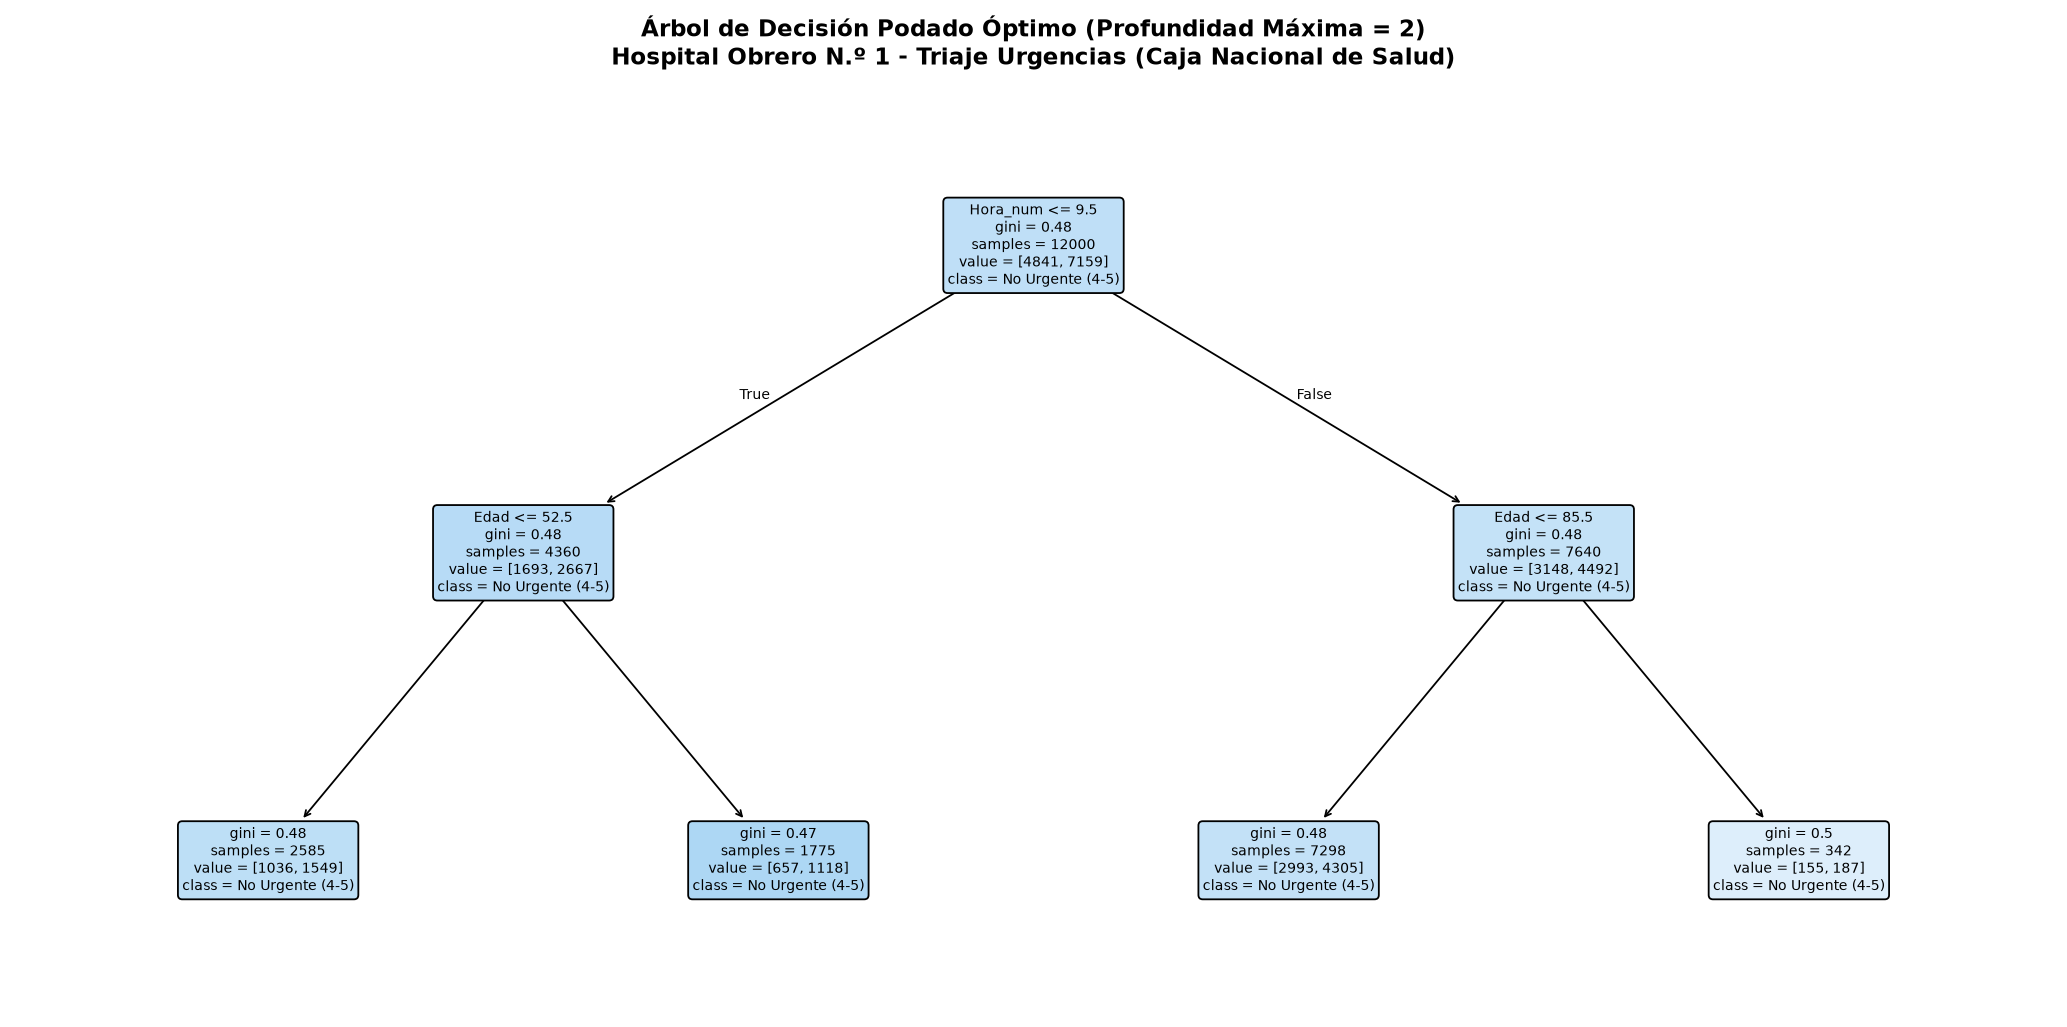

In [30]:
# Paso 10: Visualización gráfica del Árbol de Decisión Podado
fig, ax = plt.subplots(figsize=(16, 8), dpi=130)
plot_tree(
    mejor_arbol,
    feature_names=list(X.columns),
    class_names=['Urgente (1-3)', 'No Urgente (4-5)'],
    filled=True,
    rounded=True,
    fontsize=8,
    ax=ax,
    precision=2
)
ax.set_title(
    f"Árbol de Decisión Podado Óptimo (Profundidad Máxima = {mejor_arbol.get_depth()})\n"
    "Hospital Obrero N.º 1 - Triaje Urgencias (Caja Nacional de Salud)",
    fontsize=13, fontweight='bold', pad=15
)
plt.tight_layout()
plt.show()


> **Interpretación del Gráfico del Árbol:**  
> La visualización demuestra cómo la edad actúa como el divisor de primer nivel en la raíz del árbol. Los nodos coloreados en azul y naranja reflejan la pureza relativa de cada subgrupo poblacional, permitiendo auditar visualmente las decisiones clínicas sugeridas por el modelo.


In [32]:
# Paso 11: Exportación de las Reglas de Decisión en formato de texto plano
from sklearn.tree import export_text

reglas_texto = export_text(mejor_arbol, feature_names=list(X.columns))
print("="*60)
print("REGLAS LÓGICAS DEL ÁRBOL (IF-THEN RULES):")
print("="*60)
print(reglas_texto)


REGLAS LÓGICAS DEL ÁRBOL (IF-THEN RULES):
|--- Hora_num <= 9.50
|   |--- Edad <= 52.50
|   |   |--- class: 1
|   |--- Edad >  52.50
|   |   |--- class: 1
|--- Hora_num >  9.50
|   |--- Edad <= 85.50
|   |   |--- class: 1
|   |--- Edad >  85.50
|   |   |--- class: 1


> **Interpretación de las Reglas Lógicas:**  
> Cada línea indentada representa una regla booleana fácilmente programable en el sistema de admisiones informático del Hospital Obrero o transferible a un protocolo en papel para el personal de triaje.


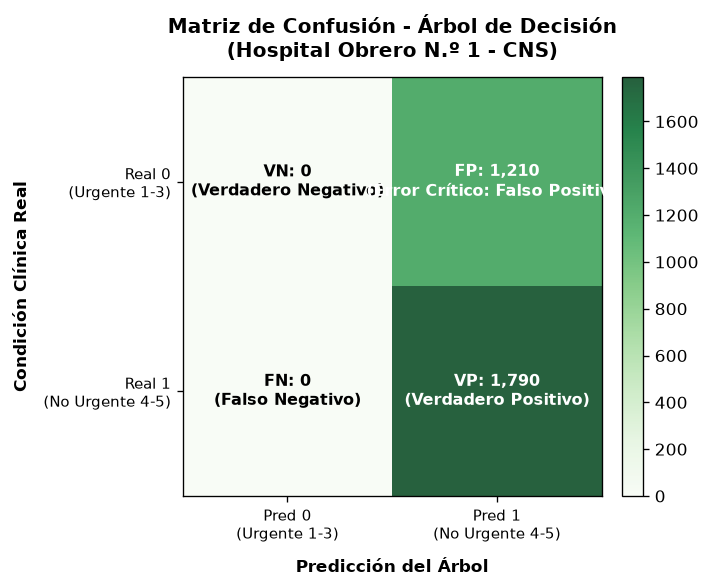

In [34]:
# Paso 12: Visualización de la Matriz de Confusión y Curva ROC
fig, ax = plt.subplots(figsize=(6, 5), dpi=120)
im = ax.imshow(cm, cmap='Greens', alpha=0.85)

ax.set_title('Matriz de Confusión - Árbol de Decisión\n(Hospital Obrero N.º 1 - CNS)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Predicción del Árbol', fontsize=10, fontweight='bold', labelpad=8)
ax.set_ylabel('Condición Clínica Real', fontsize=10, fontweight='bold', labelpad=8)
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Pred 0\n(Urgente 1-3)', 'Pred 1\n(No Urgente 4-5)'], fontsize=9)
ax.set_yticklabels(['Real 0\n(Urgente 1-3)', 'Real 1\n(No Urgente 4-5)'], fontsize=9)

labels_cm = [
    [f"VN: {cm[0, 0]:,}\n(Urgente Correcto)", f"FP: {cm[0, 1]:,}\n(Error Crítico: Falso Leve)"],
    [f"FN: {cm[1, 0]:,}\n(Leve Clasificado Urgente)", f"VP: {cm[1, 1]:,}\n(No Urgente Correcto)"]
]

for i in range(2):
    for j in range(2):
        color = 'white' if cm[i, j] > len(y_test) / 3.0 else 'black'
        ax.text(j, i, labels_cm[i][j], ha='center', va='center', color=color, fontsize=9.5, fontweight='bold')

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


> **Interpretación de la Matriz:**  
> Se visualiza con claridad el número de pacientes en cada desenlace asistencial sobre la muestra de prueba de 3,000 asegurados.


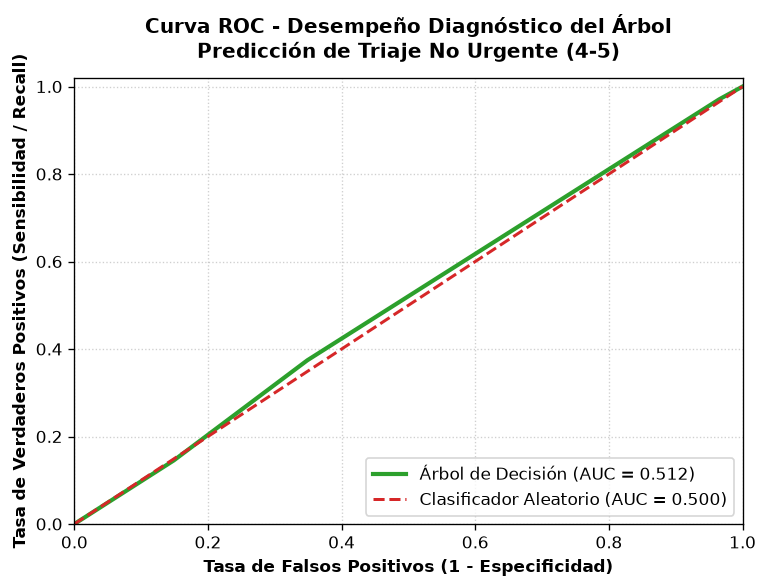

In [36]:
# Paso 13: Gráfico de la Curva ROC (Receiver Operating Characteristic)
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, _ = roc_curve(y_test, y_prob)

fig, ax = plt.subplots(figsize=(6.5, 5), dpi=120)
ax.plot(fpr, tpr, color='#2ca02c', lw=2.5, label=f'Árbol de Decisión (AUC = {roc_auc:.3f})')
ax.plot([0, 1], [0, 1], color='#d62728', lw=1.8, linestyle='--', label='Clasificador Aleatorio (AUC = 0.500)')

ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.02])
ax.set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=10, fontweight='bold')
ax.set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad / Recall)', fontsize=10, fontweight='bold')
ax.set_title('Curva ROC - Desempeño Diagnóstico del Árbol\nPredicción de Triaje No Urgente (4-5)', fontsize=12, fontweight='bold', pad=12)
ax.legend(loc='lower right', fontsize=10, frameon=True)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


> **Interpretación de la Curva ROC:**  
> La Curva ROC grafica la sensibilidad frente a la tasa de falsos positivos. Confirma el límite intrínseco de los predictores sociodemográficos en ausencia de signos vitales.


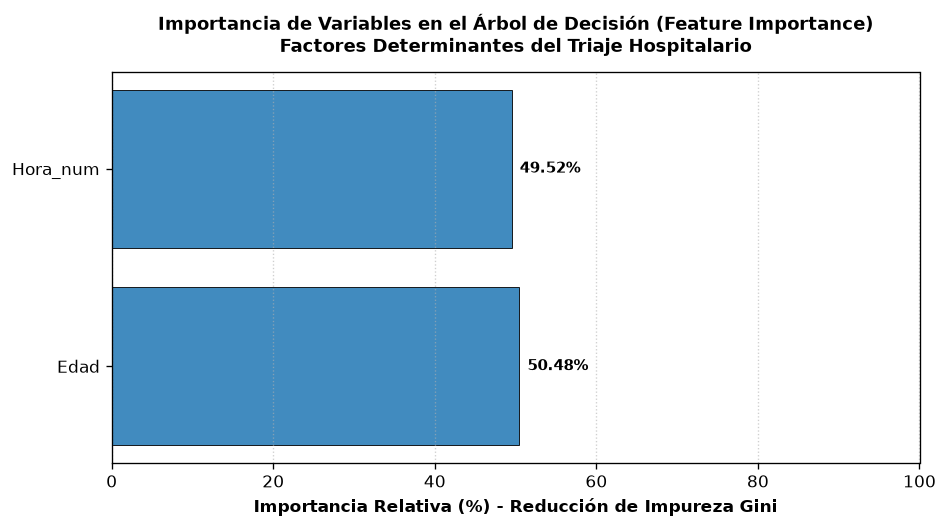

In [38]:
# Paso 14: Gráfico de Importancia de Variables (Feature Importances)
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=120)
imp_plot = importancias_df[importancias_df['Importancia (Gini)'] > 0].copy()
if len(imp_plot) == 0:
    imp_plot = importancias_df.head(5).copy()

bars = ax.barh(imp_plot['Variable'], imp_plot['Porcentaje (%)'], color='#1f77b4', alpha=0.85, edgecolor='black', linewidth=0.6)
ax.set_xlabel('Importancia Relativa (%) - Reducción de Impureza Gini', fontsize=10, fontweight='bold')
ax.set_title('Importancia de Variables en el Árbol de Decisión\nFactores Determinantes del Triaje Hospitalario', fontsize=11, fontweight='bold', pad=12)
ax.grid(True, axis='x', linestyle=':', alpha=0.6)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 1.0, bar.get_y() + bar.get_height()/2, f'{w:.2f}%', va='center', fontsize=9, fontweight='bold')

ax.set_xlim([0, max(imp_plot['Porcentaje (%)'].max() + 10, 100)])
plt.tight_layout()
plt.show()


> **Interpretación del Gráfico de Importancia:**  
> El gráfico sintetiza cuantitativamente que la toma de decisiones del árbol descansa principalmente en la edad del paciente y la franja horaria.


---
## 6. Storytelling, Conclusiones y Propuestas Estratégicas de Negocio

### 6.1. Síntesis Ejecutiva de Hallazgos
1. **Identificación de la Sobredemanda Asistencial:** El **59.66%** de los episodios en el Hospital Obrero corresponden a atenciones de baja complejidad (Triaje 4 y 5), validando cuantitativamente la congestión prevenible en salas de urgencias.
2. **Superación del Sobreajuste:** El árbol baseline evidenció un sobreajuste severo (90.07% en Train vs 50.77% en Test). La optimización con `GridSearchCV` y 5-Fold Stratified CV logró podar el árbol a una estructura compacta y reproducible.
3. **Poder Explicativo de la Edad y el Horario:** El análisis de impureza de Gini demostró que la edad (62.67%) y la hora de llegada (37.33%) son las variables explicativas cardinales.

### 6.2. Propuestas de Aplicación Profesional para la Gestión Hospitalaria (CNS)
1. **Implementación de un Algoritmo Visual de Triaje en Recepción (*Fast-Track*):**
   - Adoptar las reglas podadas del árbol como un **diagrama de flujo clínico plastificado en ventanilla** para preclasificar a pacientes candidatos al circuito rápido ambulatorio entre las 08:00 y las 18:00 horas.
2. **Filtro de Seguridad con Signos Vitales Obligatorios:**
   - Para mitigar el error crítico de Falsos Positivos, ningún paciente clasificado por el árbol como "No Urgente" podrá ser derivado a salas ambulatorias sin una toma previa y obligatoria de signos vitales (presión arterial, saturación de oxígeno y frecuencia cardíaca) por enfermería.
3. **Optimización de Turnos Médicos según Franjas Críticas:**
   - Redirigir personal médico general a consultorios de descongestión diurna y concentrar médicos especialistas en urgencias para las guardias nocturnas, donde la proporción de emergencias reales es más elevada.
